# Beat 5: Grad-CAM (Gradient-weighted Class Activation Mapping)

**Pergunta:** E se a rede não tiver GAP e FC?

Este notebook apresenta a derivação completa do Grad-CAM em 8 passos (hook $\rightarrow y^c \rightarrow$ one-hot $\rightarrow \alpha \rightarrow \sum \alpha A \rightarrow$ ReLU $\rightarrow$ upsample $\rightarrow$ overlay), a célula-espelho `gradcam(...)` e o fecho com a imagem COCO `95786` (cup/vase, Spearman 0,467).

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

import deck
from gradcam import gradcam
from gradcam.data import CocoVal
from gradcam.metrics import spearman
from gradcam.models import load_model, preprocess, imagenet_labels, resolve_class
from gradcam.viz import figure_grid, overlay, tensor_to_numpy
from gradcam.models import denormalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("vgg16", device=device)
labels = imagenet_labels()
print(f"VGG-16 carregado em {device}")

VGG-16 carregado em cpu


## Derivação Passo a Passo (A Matemática do Grad-CAM)

1. Capturamos ativações $A^k$ e gradientes $\frac{\partial y^c}{\partial A^k}$ via hooks.
2. Calculamos os pesos de importância $\alpha_k^c = \frac{1}{Z} \sum_{i,j} \frac{\partial y^c}{\partial A_{i,j}^k}$.
3. Combinamos linearmente e aplicamos ReLU: $L_{\text{Grad-CAM}}^c = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$.

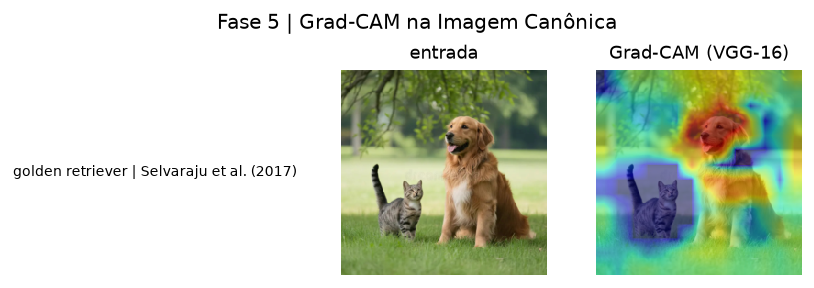

Classe: golden retriever | Grad-CAM shape: (14, 14) | max: 0.1115


In [2]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

class_idx = int(model(x).argmax(dim=1))
gc_map, _ = gradcam(model, x, class_idx=class_idx)
gc_map = gc_map.detach()

DISPLAY_HIGH, DISPLAY_GAMMA = 0.99, 0.5

fig = figure_grid(
    [
        [
            image_rgb,
            overlay(image_rgb, gc_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ]
    ],
    col_titles=("entrada", "Grad-CAM (VGG-16)"),
    row_titles=[f"{labels[class_idx]} | Selvaraju et al. (2017)"],
    suptitle="Fase 5 | Grad-CAM na Imagem Canônica",
)
plt.show()

print(f"Classe: {labels[class_idx]} | Grad-CAM shape: {tuple(gc_map.shape)} | max: {gc_map.max():.4f}")

## Fecho com Caso COCO (`95786` — Cup / Vase)

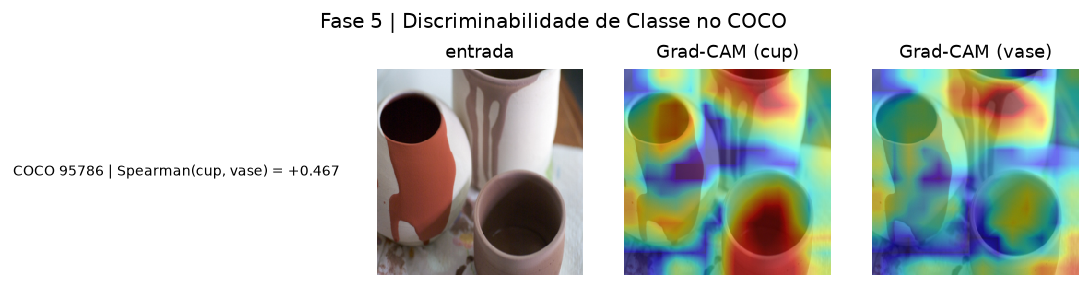

COCO 95786 | Spearman entre cup e vase: +0.4672


In [3]:
coco = CocoVal()
image_id = 95786
x_coco = preprocess(coco.load_image(image_id))
image_coco_rgb = tensor_to_numpy(denormalize(x_coco))

c_cup = resolve_class("cup", labels)
c_vase = resolve_class("vase", labels)

map_cup, _ = gradcam(model, x_coco, c_cup)
map_vase, _ = gradcam(model, x_coco, c_vase)
map_cup, map_vase = map_cup.detach(), map_vase.detach()

rho_cv = spearman(map_cup, map_vase)

fig = figure_grid(
    [
        [
            image_coco_rgb,
            overlay(image_coco_rgb, map_cup, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
            overlay(image_coco_rgb, map_vase, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ]
    ],
    col_titles=("entrada", "Grad-CAM (cup)", "Grad-CAM (vase)"),
    row_titles=[f"COCO {image_id} | Spearman(cup, vase) = {rho_cv:+.3f}"],
    suptitle="Fase 5 | Discriminabilidade de Classe no COCO",
)
plt.show()

print(f"COCO {image_id} | Spearman entre cup e vase: {rho_cv:+.4f}")